In [22]:
from helpers import load_csv_data
import numpy as np
import matplotlib.pyplot as plt

In [8]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("../dataset")

In [10]:
x_train.shape, y_train.shape

((328135, 321), (328135,))

In [20]:
unique, counts = np.unique(y_train, return_counts=True)
print(dict(zip(unique, counts)))

{np.int64(-1): np.int64(299160), np.int64(1): np.int64(28975)}


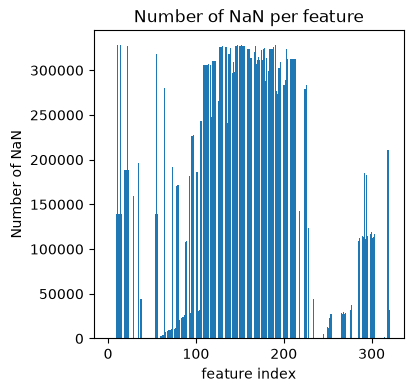

In [23]:
nan_counts = np.isnan(x_train).sum(axis=0)
plt.figure(figsize=(4,4))
plt.bar(np.arange(x_train.shape[1]), nan_counts)
plt.xlabel("feature index")
plt.ylabel("Number of NaN")
plt.title("Number of NaN per feature")
plt.show()

In [39]:
x_train.shape

(328135, 321)

In [38]:
nan_counts = np.isnan(x_train).sum(axis=0)
print(dict(zip(np.arange(x_train.shape[1]), nan_counts)))

{np.int64(0): np.int64(0), np.int64(1): np.int64(0), np.int64(2): np.int64(0), np.int64(3): np.int64(0), np.int64(4): np.int64(0), np.int64(5): np.int64(0), np.int64(6): np.int64(0), np.int64(7): np.int64(0), np.int64(8): np.int64(0), np.int64(9): np.int64(139415), np.int64(10): np.int64(139415), np.int64(11): np.int64(328103), np.int64(12): np.int64(139416), np.int64(13): np.int64(139415), np.int64(14): np.int64(328103), np.int64(15): np.int64(139433), np.int64(16): np.int64(139524), np.int64(17): np.int64(139525), np.int64(18): np.int64(188720), np.int64(19): np.int64(188720), np.int64(20): np.int64(188721), np.int64(21): np.int64(188720), np.int64(22): np.int64(327334), np.int64(23): np.int64(188719), np.int64(24): np.int64(189287), np.int64(25): np.int64(192544), np.int64(26): np.int64(2), np.int64(27): np.int64(1), np.int64(28): np.int64(0), np.int64(29): np.int64(159860), np.int64(30): np.int64(0), np.int64(31): np.int64(0), np.int64(32): np.int64(1), np.int64(33): np.int64(1), n

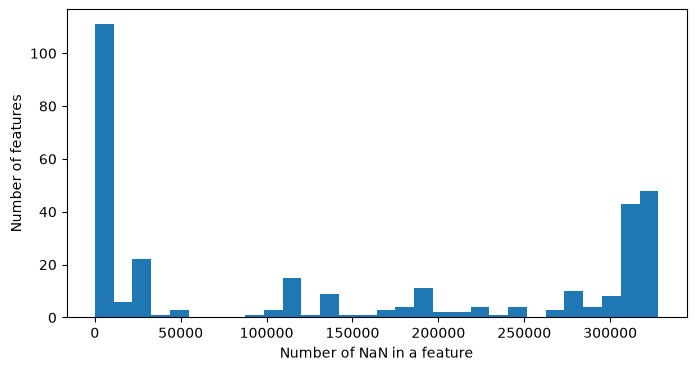

In [24]:
plt.figure(figsize=(8, 4))
plt.hist(nan_counts, bins=30)
plt.xlabel("Number of NaN in a feature")
plt.ylabel("Number of features")
plt.show()

In [33]:
import numpy as np

def classify_features(x, max_categorical=10):
    """Return a type label for each column of x, based on its distinct non-NaN values."""
    types = []
    n_unique = np.zeros(x.shape[1], dtype=int)
    for j in range(x.shape[1]):
        col = x[:, j]
        vals = np.unique(col[~np.isnan(col)])   # distinct non-missing values
        n_unique[j] = len(vals)
        if len(vals) == 0:
            types.append("all missing")
        elif len(vals) == 1:
            types.append("constant")
        elif len(vals) == 2:
            types.append("binary")
        elif len(vals) <= max_categorical:
            types.append("categorical")
        else:
            types.append("continuous")
    return np.array(types), n_unique

types, n_unique = classify_features(x_train)

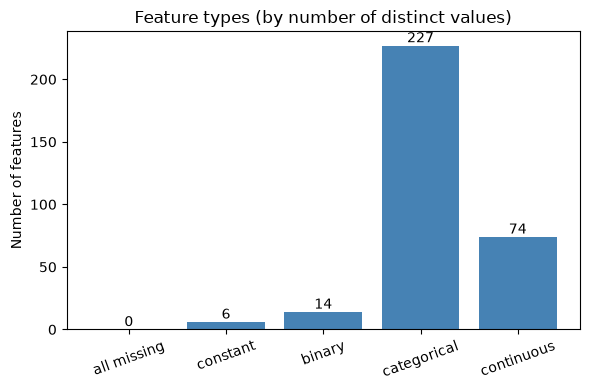

In [32]:
import matplotlib.pyplot as plt

order = ["all missing", "constant", "binary", "categorical", "continuous"]
counts = [np.sum(types == t) for t in order]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(order, counts, color="steelblue")
ax.bar_label(bars)                      # print the count on top of each bar
ax.set_ylabel("Number of features")
ax.set_title("Feature types (by number of distinct values)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("feature_types.pdf")        # PDF looks sharp in LaTeX
plt.show()

In [ ]:
import numpy as np

with open("../dataset/x_train.csv") as f: 
    header = f.readline().strip().split(",")

print(header)

['Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM', 'PVTRESD1', 'COLGHOUS', 'STATERES', 'CELLFON3', 'LADULT', 'NUMADULT', 'NUMMEN', 'NUMWOMEN', 'CTELNUM1', 'CELLFON2', 'CADULT', 'PVTRESD2', 'CCLGHOUS', 'CSTATE', 'LANDLINE', 'HHADULT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'DIABAGE2', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL2', 'NUMPHON2', 'CPDEMO1', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME2', 'INTERNET', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'FRUITJU1', 'FRUIT1', 'FVBEANS', 'FVGREEN', 'FVORANG', 'VEGETAB1', 'EXERANY2', 'EXR

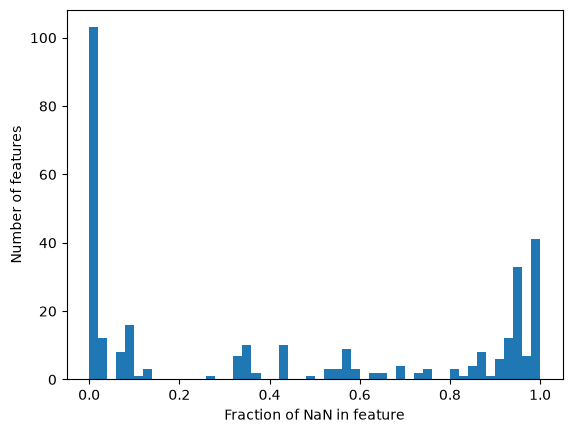

0 82 features kept
0.3 144 features kept
0.5 174 features kept
0.7 200 features kept
0.9 222 features kept


In [41]:
import numpy as np
import matplotlib.pyplot as plt

nan_frac = np.isnan(x_train).mean(axis=0)      # fraction of NaN per feature

# distribution of missing fraction across features
plt.hist(nan_frac, bins=50)
plt.xlabel("Fraction of NaN in feature"); plt.ylabel("Number of features")
plt.show()

# how many features would remain for each threshold
for t in [0, 0.3, 0.5, 0.7, 0.9]:
    print(t, (nan_frac <= t).sum(), "features kept")

threshold = 0.5
keep = nan_frac <= threshold
x_train_f = x_train[:, keep]
x_test_f = x_test[:, keep]                     # same columns for test

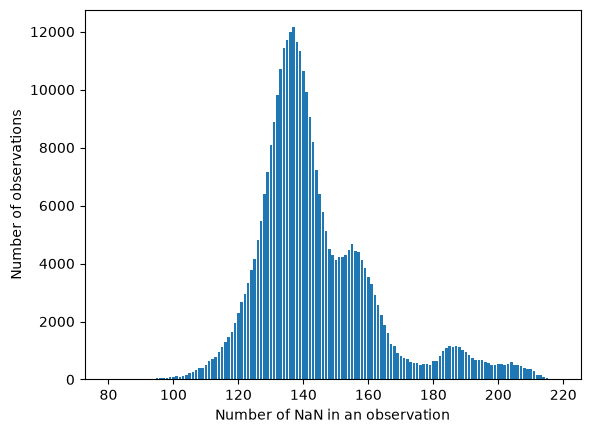

In [42]:
nan_per_row = np.isnan(x_train).sum(axis=1)
values, counts = np.unique(nan_per_row, return_counts=True)
plt.bar(values, counts)
plt.xlabel("Number of NaN in an observation"); plt.ylabel("Number of observations")
plt.show()

In [45]:
complete = ~np.isnan(x_train).any(axis=0)

x_train_c = x_train[:, complete]
x_test_c = x_test[:, complete]

In [ ]:
def mean(x):
    return np.mean(x)
def std(x):
    return np.std(x)
def standardize_data(x):
    return (x-mean(x))/std(x)
def covariance(x):
    return (x.T @ x) / (x.shape[0]-1)

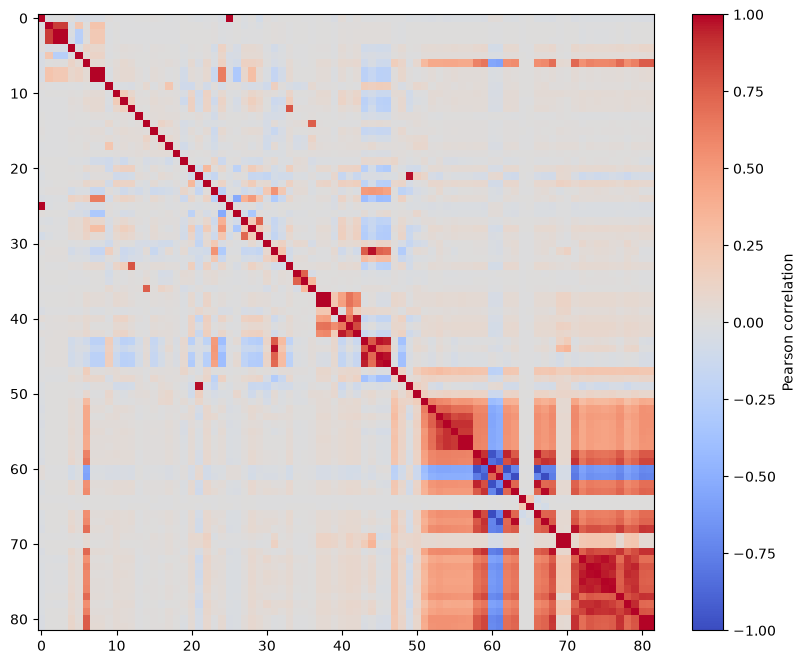

In [52]:
corr = np.corrcoef(x_train_c, rowvar=False)   # (n_feat, n_feat); columns are variables

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.show()

In [60]:
iu = np.triu_indices_from(corr, k=1)
pairs = [(i, j, corr[i, j]) for i, j in zip(*iu) if abs(corr[i, j]) > 0.8]
pairs.sort(key=lambda p: -abs(p[2]))
print(len(pairs))

86


In [54]:
corr_y = [np.corrcoef(x_train_c[:, k], y_train)[0, 1] for k in range(x_train_c.shape[1])]

In [67]:
def drop_correlated(x, y=None, threshold=0.9):
    corr = np.corrcoef(x, rowvar=False)                 # constant columns -> 0
    n = corr.shape[0]

    # relevance used to decide which of a pair to keep
    if y is not None:
        rel = np.array([abs(np.nan_to_num(np.corrcoef(x[:, k], y)[0, 1])) for k in range(n)])
    else:
        rel = np.zeros(n)

    keep = np.ones(n, dtype=bool)
    for i in range(n):
        if not keep[i]:
            continue                            # already removed: can't cause more drops
        for j in range(i + 1, n):
            if keep[j] and abs(corr[i, j]) > threshold:
                # drop the less relevant of the two
                if rel[j] > rel[i]:
                    keep[i] = False
                    break                       # i is gone, stop comparing it
                keep[j] = False
    return keep

keep = drop_correlated(x_train_c, y_train, threshold=0.8)
print(keep.sum(), "features kept of", keep.size)

x_train_u = x_train_c[:, keep]
x_test_u = x_test_c[:, keep]                    # same mask on test

51 features kept of 82


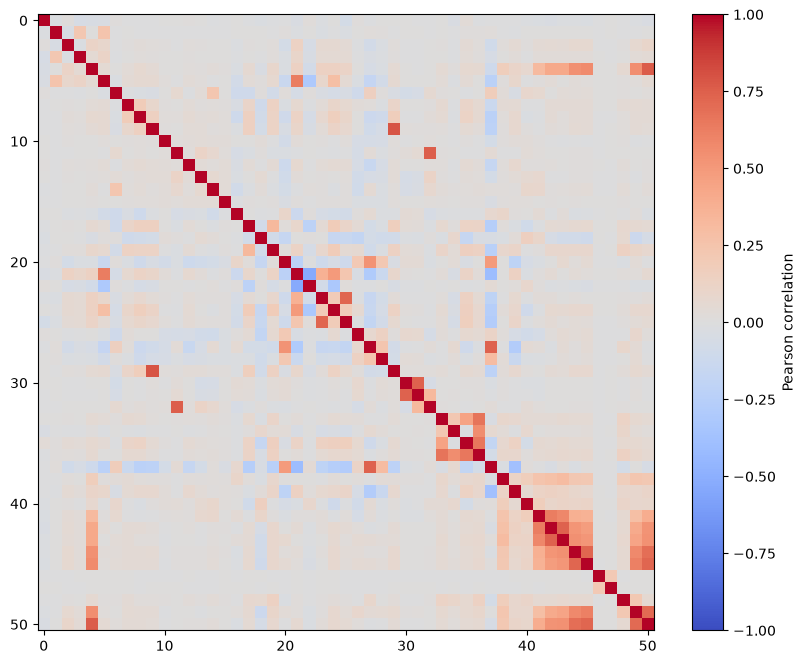

In [68]:
corr = np.corrcoef(x_train_u, rowvar=False)   # (n_feat, n_feat); columns are variables

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.show()

In [73]:
import os
import numpy as np

with open(os.path.join("../dataset", "x_train.csv")) as f:
    names = np.array(f.readline().strip().split(","))
     # expect "Id"
names = names[1:]      # now 321 names, matching x_train's columns
names_c = names[complete]
names_u = names_c[keep]
print(len(names_u), x_train_u.shape[1]) 

51 51


In [76]:
print(names_u)

['_STATE' 'FMONTH' 'IDAY' 'IYEAR' 'DISPCODE' 'SEQNO' 'MENTHLTH' 'HLTHPLN1'
 'PERSDOC2' 'BLOODCHO' 'CVDSTRK3' 'ASTHMA3' 'CHCOCNCR' 'CHCCOPD1'
 'ADDEPEV2' 'CHCKIDNY' 'SEX' 'MARITAL' 'EDUCA' 'RENTHOM1' 'EMPLOY1'
 'QSTVER' '_RAWRAKE' '_WT2RAKE' '_DUALUSE' '_LLCPWT' '_RFHLTH' '_HCVU651'
 '_RFHYPE5' '_CHOLCHK' '_LTASTH1' '_CASTHM1' '_ASTHMS1' '_PRACE1'
 '_HISPANC' '_RACE' '_RACEG21' '_AGE80' '_RFBMI5' '_CHLDCNT' '_INCOMG'
 '_SMOKER3' '_RFSMOK3' 'DRNKANY5' '_FRTLT1' '_VEGLT1' '_FRT16' '_VEG23'
 'MAXVO2_' '_PAREC1' '_RFSEAT3']


In [82]:
drop = ["_STATE", "FMONTH", "IDAY", "IYEAR", "DISPCODE", "SEQNO", "QSTVER"]

mask = ~np.isin(names_u, drop)
print("dropping:", names_u[~mask])

x_train_d = x_train_u[:, mask]
names_d = names_u[mask]
print(x_train_d.shape)
print(names_d)

dropping: ['_STATE' 'FMONTH' 'IDAY' 'IYEAR' 'DISPCODE' 'SEQNO' 'QSTVER']
(328135, 44)
['MENTHLTH' 'HLTHPLN1' 'PERSDOC2' 'BLOODCHO' 'CVDSTRK3' 'ASTHMA3'
 'CHCOCNCR' 'CHCCOPD1' 'ADDEPEV2' 'CHCKIDNY' 'SEX' 'MARITAL' 'EDUCA'
 'RENTHOM1' 'EMPLOY1' '_RAWRAKE' '_WT2RAKE' '_DUALUSE' '_LLCPWT' '_RFHLTH'
 '_HCVU651' '_RFHYPE5' '_CHOLCHK' '_LTASTH1' '_CASTHM1' '_ASTHMS1'
 '_PRACE1' '_HISPANC' '_RACE' '_RACEG21' '_AGE80' '_RFBMI5' '_CHLDCNT'
 '_INCOMG' '_SMOKER3' '_RFSMOK3' 'DRNKANY5' '_FRTLT1' '_VEGLT1' '_FRT16'
 '_VEG23' 'MAXVO2_' '_PAREC1' '_RFSEAT3']


constant: 0 | binary: 3 | 3-10 values: 35 | >10 values: 6
SEX                       2  min=1 max=2  [1. 2.]
_FRT16                    2  min=0 max=1  [0. 1.]
_VEG23                    2  min=0 max=1  [0. 1.]
_HISPANC                  3  min=1 max=9  [1. 2. 9.]
_HCVU651                  3  min=1 max=9  [1. 2. 9.]
_RFHYPE5                  3  min=1 max=9  [1. 2. 9.]
_RFBMI5                   3  min=1 max=9  [1. 2. 9.]
_LTASTH1                  3  min=1 max=9  [1. 2. 9.]
_CASTHM1                  3  min=1 max=9  [1. 2. 9.]
_DUALUSE                  3  min=1 max=9  [1. 2. 9.]
_VEGLT1                   3  min=1 max=9  [1. 2. 9.]
_RFSEAT3                  3  min=1 max=9  [1. 2. 9.]
_RFSMOK3                  3  min=1 max=9  [1. 2. 9.]
_FRTLT1                   3  min=1 max=9  [1. 2. 9.]
_RFHLTH                   3  min=1 max=9  [1. 2. 9.]
_RACEG21                  3  min=1 max=9  [1. 2. 9.]
CVDSTRK3                  4  min=1 max=9  [1. 2. 7. 9.]
_ASTHMS1                  4  min=1 max=9  [1. 2

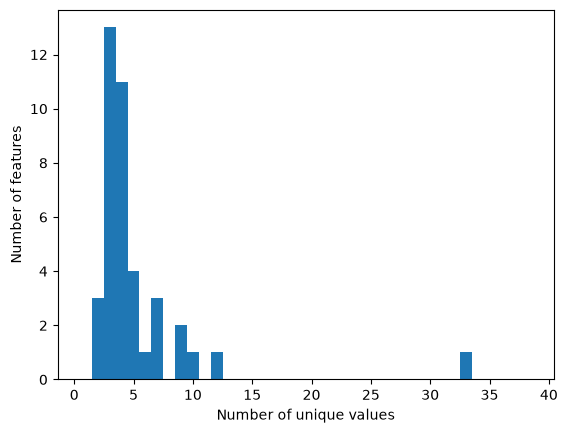

In [83]:
import numpy as np
import matplotlib.pyplot as plt

n_unique = np.array([len(np.unique(x_train_d[:, k])) for k in range(x_train_d.shape[1])])

# summary by type
binary = n_unique == 2
constant = n_unique == 1
categorical = (n_unique >= 3) & (n_unique <= 10)
continuous = n_unique > 10
print("constant:", constant.sum(), "| binary:", binary.sum(),
      "| 3-10 values:", categorical.sum(), "| >10 values:", continuous.sum())

# per-feature table, sorted by number of unique values
for k in np.argsort(n_unique):
    vals = np.unique(x_train_d[:, k])
    preview = vals if len(vals) <= 8 else np.r_[vals[:4], [np.nan], vals[-3:]]
    print(f"{names_d[k]:20s} {n_unique[k]:6d}  min={vals.min():g} max={vals.max():g}  {preview}")

# distribution of the unique-value counts
plt.hist(n_unique, bins=np.arange(1, 40) - 0.5)
plt.xlabel("Number of unique values"); plt.ylabel("Number of features")
plt.show()

In [85]:
import numpy as np

def one_hot_by_name(x, names, cat_names, cats=None):
    """One-hot encode only the named columns of x.
    cats: dict name -> categories. If None, learn them from x (use on TRAIN)."""
    col = {n: i for i, n in enumerate(names)}
    missing = [n for n in cat_names if n not in col]
    if missing:
        raise ValueError(f"Not in the current features: {missing}")

    if cats is None:
        cats = {n: np.unique(x[:, col[n]]) for n in cat_names}

    cat_idx = {col[n] for n in cat_names}
    rest_idx = [i for i in range(len(names)) if i not in cat_idx]

    blocks = [x[:, rest_idx]]
    new_names = [names[i] for i in rest_idx]
    for n in cat_names:
        blocks.append((x[:, [col[n]]] == cats[n]).astype(float))
        new_names += [f"{n}={c:g}" for c in cats[n]]

    return np.hstack(blocks), np.array(new_names), cats

In [86]:
cat_names = [
    "_CASTHM1", "_DUALUSE", "_VEGLT1", "_RFSEAT3", "_RFSMOK3", "_FRTLT1",
    "_RFHLTH", "_RACEG21", "CVDSTRK3", "_ASTHMS1", "_CHOLCHK", "CHCKIDNY",
    "CHCOCNCR", "CHCCOPD1", "ADDEPEV2", "BLOODCHO", "ASTHMA3", "DRNKANY5",
    "HLTHPLN1", "_SMOKER3", "PERSDOC2", "RENTHOM1", "_PAREC1", "_INCOMG",
    "EDUCA", "MARITAL", "_CHLDCNT", "EMPLOY1", "_RACE", "_PRACE1",
]

# sanity check: are they all still in the current features?
print([n for n in cat_names if n not in set(names_d)])   # should print []

x_train_oh, names_oh, cats = one_hot_by_name(x_train_d, names_d, cat_names)
print(x_train_oh.shape, len(names_oh))

[]
(328135, 157) 157
